# 05 · Improving the document's method at 100 m

**Question:** MOLUSCE's logistic regression placed change better than the methodology document's method in notebook 07 (19.3–19.7 % against 18.5 % with the same amount, test window). Does what it does better improve our method, by more than the seed noise?

The document's method (notebook 04) is now run with three seeds (42, 1, 2) in every window. Three candidates are compared with it on the **validation window** (2022 → 2023 → 2024), three seeds each; only a candidate that beats it there by more than the spread of the seeds (Bouthillier et al. 2021) goes on to the **test** and **backtest** windows, which are reported, not used to choose. Section 7 tests the two other parts of the 250 m improved method, contagion and FLUS's network. Each forecast is placed with `main`'s allocator, with the observed amount of change and with the platform's projected amount, and scored with notebook 04's Figure of Merit. Runs: `scripts/run05.py`; code: `scripts/decisions100.py`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import decisions100 as M
import tools100 as T
D = M.D
C, G, H = D.C, D.G, D.C.H

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30, "display.width", 200)
WINDOWS = ["backtest", "validation", "test"]
S = M.scores()
summary = (S.groupby(["phase", "demand", "method"])["FoM"]
           .agg(mean="mean", spread=lambda v: v.max() - v.min(), seeds="size"))
print(f"{len(S)} scores; main's own figure_of_merit agrees with ours within {(S['FoM'] - S['platform FoM']).abs().max():.3f} points")

172 scores; main's own figure_of_merit agrees with ours within 0.005 points


## 1 · The candidates

| Method | What it adds | Source |
|---|---|---|
| Document's method | Expander model per transition (Random Forest), the 12 predictors and the share of the destination class within 5 cells (notebook 04) | Soares-Filho et al. (2002); Verburg et al. (2002) |
| Document + 3 × 3 class shares | the share of each class in the 3 × 3 window around a cell (7 more predictors), the window MOLUSCE's regression reads | Verburg et al. (2004): the classes around a cell explain where land use changes |
| MOLUSCE's regression (copy) | MOLUSCE 5.1's logistic regression, rewritten in Python: one regression for all transitions, with the 3 × 3 window of classes and of the 12 predictors as inputs, 50,000 random training cells, 100 iterations | NextGIS (2025); logistic regression as in CLUE-S (Verburg et al. 2002) |
| Blend: document + regression | for each transition, the document's map and the regression's map turned into ranks among the cells of the start class and averaged, with equal weights | Clemen (1989): an equal-weight average of different forecasts is usually better than the best single one |

All are trained on the first interval of the window (start map and predictors of its first year) and forecast from its middle year, as the document's method; none reads the year it forecasts. Clouds are left out in all.

## 2 · The seed spread of the document's method

The document's method was run with one seed in notebook 04. With three seeds:

In [2]:
doc = summary.xs("document", level="method").reindex(pd.MultiIndex.from_product([WINDOWS, ["observed", "projected"]]))
doc.index.names = ["window", "amount"]
C.save("05_document_seeds.csv", doc)
doc.round(2)

mean  spread  seeds
window     amount                         
backtest   observed   15.15    0.08      3
           projected  14.49    0.08      3
validation observed   15.94    0.38      3
           projected  13.41    0.31      3
test       observed   18.60    0.20      3
           projected  14.08    0.19      3

**Reading:** the seed changes the document's score by 0.1–0.4 points. A candidate's gain has to be larger than that to count.

## 3 · The candidates on the validation window

Mean of three seeds; the gain over the document's method counts if it is larger than the larger of the two seed spreads.

In [3]:
rows = []
for demand in ("observed", "projected"):
    ref = summary.loc[("validation", demand, "document")]
    for method, label in M.METHODS.items():
        s = summary.loc[("validation", demand, method)]
        gain = s["mean"] - ref["mean"]
        noise = max(s["spread"], ref["spread"])
        rows.append({"amount": demand, "method": label, "FoM, mean": s["mean"], "seed spread": s["spread"],
                     "gain over document": gain if method != "document" else np.nan,
                     "gain > spread": ("yes" if gain > noise else "no") if method != "document" else ""})
val = pd.DataFrame(rows).set_index(["amount", "method"])
C.save("05_validation.csv", val)
val.round(2)

FoM, mean  seed spread  gain over document gain > spread
amount    method                                                                                         
observed  Document's method                          15.94         0.38                 NaN              
          Document + 3 × 3 class shares              17.10         0.42                1.16           yes
          MOLUSCE's regression (copy)                17.54         0.15                1.60           yes
          Blend: document + regression               18.01         0.21                2.08           yes
          Document + contagion                       17.19         0.29                1.25           yes
          FLUS's network (copy)                      16.42         0.10                0.49           yes
          Blend with contagion                       18.70         0.19                2.76           yes
          Blend + FLUS's network                     18.32         0.16                2.38           yes
          Blend with contagion + FLUS's network      18.85         0.14                2.91           yes
          Blend, document weight 0.25                18.18         0.11                2.24           yes
          Blend, document weight 0.75                17.33         0.33                1.39           yes
projected Document's method                          13.41         0.31                 NaN              
          Document + 3 × 3 class shares              14.26         0.15                0.85           yes
          MOLUSCE's regression (copy)                14.75         0.06                1.34           yes
          Blend: document + regression               15.08         0.17                1.67           yes
          Document + contagion                       14.48         0.27                1.07           yes
          FLUS's network (copy)                      13.81         0.15                0.40           yes
          Blend with contagion                       15.70         0.18                2.30           yes
          Blend + FLUS's network                     15.33         0.21                1.92           yes
          Blend with contagion + FLUS's network      15.78         0.19                2.37           yes
          Blend, document weight 0.25                15.20         0.07                1.80           yes
          Blend, document weight 0.75                14.55         0.25                1.15           yes

**Reading:**

* **All three candidates beat the document's method by more than the seed noise.** The 3 × 3 class shares add 1.2 points with the observed amount, MOLUSCE's regression alone 1.6, and the blend of the two 2.1; with the projected amount 0.9, 1.3 and 1.7.
* **The blend is best,** 0.5 above the regression alone with the observed amount and 0.3 with the projected one, more than either's seed spread: the two models are wrong in different places, so their average is better than either (Clemen 1989).
* The regression alone is the most stable across seeds (spread under 0.2).
* So the blend goes to the test and backtest windows.

## 4 · The blend on the test and backtest windows

Neither window was used to choose the blend.

In [4]:
rows = []
for phase in WINDOWS:
    for demand in ("observed", "projected"):
        a, b = summary.loc[(phase, demand, "document")], summary.loc[(phase, demand, "blend")]
        rows.append({"window": phase, "amount": demand, "document": a["mean"], "document spread": a["spread"],
                     "blend": b["mean"], "blend spread": b["spread"], "gain": b["mean"] - a["mean"]})
held = pd.DataFrame(rows).set_index(["window", "amount"])
C.save("05_blend_vs_document.csv", held)
held.round(2)

document  document spread  blend  blend spread  gain
window     amount                                                         
backtest   observed      15.15             0.08  16.85          0.01  1.70
           projected     14.49             0.08  16.10          0.04  1.61
validation observed      15.94             0.38  18.01          0.21  2.08
           projected     13.41             0.31  15.08          0.17  1.67
test       observed      18.60             0.20  20.01          0.18  1.41
           projected     14.08             0.19  15.26          0.19  1.18

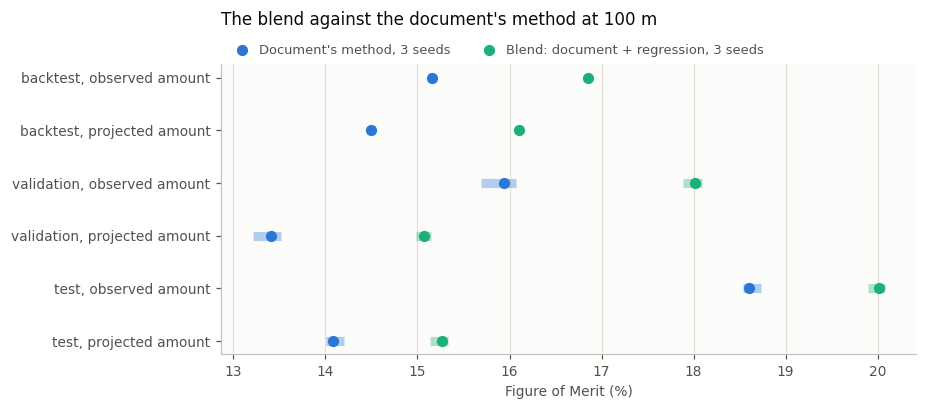

In [5]:
rows_ = list(held.index)[::-1]
y = np.arange(len(rows_))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for col, colour, label in (("document", H.SERIES[0], "Document's method"), ("blend", H.SERIES[2], "Blend: document + regression")):
    lo = [S[(S.method == col) & (S.phase == w) & (S.demand == d)]["FoM"].min() for w, d in rows_]
    hi = [S[(S.method == col) & (S.phase == w) & (S.demand == d)]["FoM"].max() for w, d in rows_]
    ax.hlines(y, lo, hi, color=colour, linewidth=6, alpha=0.35, zorder=1)
    ax.scatter(held.loc[rows_, col], y, s=40, color=colour, zorder=3, label=f"{label}, 3 seeds")
ax.set_yticks(y, [f"{w}, {d} amount" for w, d in rows_])
ax.set_xlabel("Figure of Merit (%)", color=H.INK_2)
H.style_axes(ax)
ax.set_title("The blend against the document's method at 100 m", loc="left", color=H.INK, fontsize=11, pad=26)
ax.legend(frameon=False, fontsize=8.5, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, labelcolor=H.INK_2,
          handletextpad=0.3, borderaxespad=0.2)
plt.tight_layout(); plt.show()

**Reading:**

* **The blend beats the document's method in every window and with both amounts,** by 1.2–1.7 points of Figure of Merit, six to twenty times the larger seed spread (0.08–0.20).
* **On the test window it scores 20.0 % with the observed amount,** above every tool of notebook 07 with the same amount, MOLUSCE's own regression included (19.3–19.7 %).
* The gain on the held-out windows (1.2–1.7) is a little smaller than on the validation window (1.7–2.1), where it was chosen, as expected.
* **Over all of Guinea** (test window, observed amount, seed 42) the blend turns 61,000 misses into hits and has 55,000 fewer false alarms than the document's method, with the same number of changed cells.

## 5 · Check: the regression copy against MOLUSCE's own code

The copy is a rewrite: scikit-learn's L-BFGS solver instead of MOLUSCE's BFGS code, the rest as MOLUSCE does it (`scripts/molusce_run.py` ran MOLUSCE's own code for notebook 07). Test window, observed amount; the copy was run on test with seed 42 only for this check.

In [6]:
Tm = T.scores()
lr_code = Tm.loc[[k for k in Tm.index if k.startswith("molusce_lr") and k.endswith("_same")], "FoM"]
copy = S[(S.method == "lr") & (S.phase == "test") & (S.demand == "observed")]["FoM"]
pd.Series({"MOLUSCE's code, 3 seeds (notebook 07)": f"{lr_code.min():.2f}–{lr_code.max():.2f}",
           "Copy, seed 42": f"{copy.iloc[0]:.2f}"}, name="FoM %, test, same amount")

MOLUSCE's code, 3 seeds (notebook 07)    19.34–19.72
Copy, seed 42                                  19.85
Name: FoM %, test, same amount, dtype: object

**Reading:** the copy scores 0.1 point above MOLUSCE's best seed, so it reproduces MOLUSCE's regression; the small excess is likely its solver getting further in the 100 iterations both are allowed.

## 6 · The amount of change

As it runs, the blend gets the platform's projected amount: a trend fitted per transition on every interval since 2017, 17–27 % below what happened (notebook 04). Three simpler amounts were compared with it, with the blend's maps and `main`'s allocator: the transitions of the last interval (a one-step Markov projection, as MOLUSCE and the 250 m runs use; Mas et al. 2014) and the mean of the last two or three intervals. The choice was fixed on the validation window before the test and backtest windows were run (`scripts/run05_amounts.py`).

In [7]:
A = M.amount_scores()
amt = A.groupby(["phase", "amount"], sort=False).agg(**{
    "FoM, mean": ("FoM", "mean"), "seed spread": ("FoM", lambda v: v.max() - v.min()),
    "cells changed (millions)": ("predicted change (cells)", "mean")})
amt["cells changed (millions)"] /= 1e6
amt["gain over trend"] = amt["FoM, mean"] - amt.xs("trend", level="amount")["FoM, mean"].reindex(amt.index, level="phase")
amt = amt.reindex(WINDOWS, level="phase")
C.save("05_amount.csv", amt)
amt.round(2)

FoM, mean  seed spread  cells changed (millions)  gain over trend
phase      amount                                                                                
backtest   trend                    16.10         0.04                      2.13             0.00
           last interval            16.15         0.03                      2.62             0.05
           mean of 2 intervals      16.05         0.03                      2.53            -0.05
           mean of 3 intervals      16.68         0.02                      2.60             0.58
validation trend                    15.08         0.17                      2.21             0.00
           last interval            17.17         0.17                      2.61             2.09
           mean of 2 intervals      17.57         0.19                      2.62             2.50
           mean of 3 intervals      17.43         0.19                      2.56             2.36
test       trend                    15.26         0.19                      2.32             0.00
           last interval            12.87         0.13                      2.69            -2.39
           mean of 2 intervals      14.25         0.16                      2.65            -1.02
           mean of 3 intervals      13.92         0.15                      2.64            -1.34

**Reading:**

* **On the validation window every recent-interval amount beats the trend by about 2 points,** the mean of two intervals most (+2.5, spread 0.2); it was chosen.
* **It does not hold on the other windows:** 1.0 point below the trend on test, level on backtest (−0.05). Each window prefers a different rule (validation the mean of two, test the trend, backtest the mean of three), so none of them is reliably better, and the platform's trend is kept.
* So the forecast keeps the platform's trend for *how much* land changes, and uses the blend for *where* it changes.

**Why:** the largest changes in Esri's maps are the savanna–trees flicker (notebook 01), and its direction turns from year to year. The main transitions, in thousands of cells:

In [8]:
rows = []
for phase in ("validation", "test"):
    b, c = M.PHASES[phase][1:]
    obs = D.observed_demand(b, c)
    obs = obs.loc[[i for i in obs.index if i not in M.INVALID], [j for j in obs.columns if j not in M.INVALID]]
    for i in obs.index:
        if i in obs.columns:
            obs.loc[i, i] = 0
    for (f, t), name in (((2, 11), "trees → rangeland"), ((11, 2), "rangeland → trees")):
        rows.append({"window": phase, "transition": name, "observed": obs.loc[f, t],
                     **{k: M.amount(phase, k).loc[f, t] for k in M.AMOUNTS}})
mix = (pd.DataFrame(rows).set_index(["window", "transition"]) / 1e3).round(0).astype(int)
C.save("05_amount_flicker.csv", mix)
mix

observed  trend  last interval  mean of 2 intervals  mean of 3 intervals
window     transition                                                                                 
validation trees → rangeland      1481    472           1021                 1218                 1201
           rangeland → trees       878   1438           1300                 1103                 1062
test       trees → rangeland       666    758           1481                 1251                 1306
           rangeland → trees      2168   1232            878                 1089                 1028

**Reading:** in the validation year (2023 → 2024) most of the flicker went from trees to rangeland, as in the years before, so the recent intervals were right. In the test year (2024 → 2025) it turned: 2.2 million cells went from rangeland to trees, and the recent intervals still forecast last year's direction. No amount rule built from past maps can forecast the direction of a flicker that is largely classification noise in Esri's maps (notebook 01); this is the part of the error that belongs to the amount, not to where change is placed.

## 7 · Second round: contagion and FLUS's network

The improved method at 250 m (250 m notebook 11) has two parts the blend does not:

* **Contagion:** six more inputs for the document's Random Forest, per destination class, all about last year's *new* change into that class nearby: its share within 0.75, 2.5 and 5 km, any new change within 2.5 km, the distance to the nearest, and the last three years within 2.5 km. Land tends to change where it has just changed (Rosa et al. 2013). "New" means into a class the cell had not held in any map since 2017.
* **FLUS's neural network** as a third member of the average (Liu et al. 2017; the copy of notebook 07).

Both use maps up to the forecast's start year only. Same rule as section 3: chosen on the validation window, three seeds, against the blend (`scripts/run05_second.py`).

In [9]:
SECOND = ["blend", "contagion", "flusnet", "blendc", "blend3", "blend3c"]
rows = []
for demand in ("observed", "projected"):
    ref = summary.loc[("validation", demand, "blend")]
    for method in SECOND:
        s = summary.loc[("validation", demand, method)]
        gain = s["mean"] - ref["mean"]
        rows.append({"amount": demand, "method": M.METHODS[method], "FoM, mean": s["mean"], "seed spread": s["spread"],
                     "gain over blend": gain if method != "blend" else np.nan,
                     "gain > spread": ("yes" if gain > max(s["spread"], ref["spread"]) else "no") if method != "blend" else ""})
second = pd.DataFrame(rows).set_index(["amount", "method"])
C.save("05_second_validation.csv", second)
second.round(2)

FoM, mean  seed spread  gain over blend gain > spread
amount    method                                                                                      
observed  Blend: document + regression               18.01         0.21              NaN              
          Document + contagion                       17.19         0.29            -0.83            no
          FLUS's network (copy)                      16.42         0.10            -1.59            no
          Blend with contagion                       18.70         0.19             0.68           yes
          Blend + FLUS's network                     18.32         0.16             0.31           yes
          Blend with contagion + FLUS's network      18.85         0.14             0.83           yes
projected Blend: document + regression               15.08         0.17              NaN              
          Document + contagion                       14.48         0.27            -0.60            no
          FLUS's network (copy)                      13.81         0.15            -1.27            no
          Blend with contagion                       15.70         0.18             0.63           yes
          Blend + FLUS's network                     15.33         0.21             0.25           yes
          Blend with contagion + FLUS's network      15.78         0.19             0.70           yes

**Reading:**

* **Alone, neither part beats the blend.** The document's method with contagion scores 17.2 % (1.2 above the document's method alone), FLUS's network 16.4 %.
* **Inside the average, both help on validation.** The document with contagion in place of the plain document gains 0.7 (blend with contagion, 18.7 %); FLUS's network as a third member gains 0.3; both together gain 0.8 (18.85 %).
* **Chosen on validation:** the blend with contagion and FLUS's network scored highest there and beat the blend by more than the seed spread, so by the rule of section 3 (choose on the validation window only, with a gain larger than the seed spread; Bouthillier et al. 2021; Cawley & Talbot 2010) it was the candidate to confirm on the test and backtest windows.

### On the test and backtest windows

Mean of three seeds; every candidate is shown, but only the chosen one was to be confirmed here.

In [10]:
cols = ["document", "contagion", "flusnet", "blend", "blendc", "blend3", "blend3c"]
held2 = (summary.reset_index().query("phase in ['test', 'backtest'] and method in @cols")
         .pivot_table(index=["phase", "demand"], columns="method", values="mean")[cols])
held2["largest seed spread"] = (summary.reset_index().query("phase in ['test', 'backtest'] and method in @cols")
                                .groupby(["phase", "demand"])["spread"].max())
held2 = held2.rename(columns=M.METHODS).reindex(["test", "backtest"], level="phase")
held2.index.names = ["window", "amount"]
C.save("05_second_heldout.csv", held2)
held2.round(2)

method              Document's method  Document + contagion  FLUS's network (copy)  Blend: document + regression  Blend with contagion  Blend + FLUS's network  Blend with contagion + FLUS's network  \
window   amount                                                                                                                                                                                         
test     observed               18.60                 19.65                  18.53                         20.01                 20.59                   20.00                                  20.40   
         projected              14.08                 14.97                  13.85                         15.26                 15.74                   15.25                                  15.60   
backtest observed               15.15                 15.56                  13.96                         16.85                 17.06                   16.43                                  16.60   
         projected              14.49                 14.88                  13.32                         16.10                 16.31                   15.71                                  15.87   

method              largest seed spread  
window   amount                          
test     observed                  0.20  
         projected                 0.24  
backtest observed                  0.21  
         projected                 0.20

**Reading:**

* **The chosen blend did not hold.** It gains 0.4 and 0.3 on test but loses 0.25 and 0.23 on backtest, more than the seed spread of either (0.01 for the blend, 0.09 for the chosen one). It is not adopted.
* **FLUS's network is the part that fails.** Alone it is 1.2 points below the document's method on backtest (14.0 against 15.2), and every blend that includes it loses on backtest.
* **Contagion helps in both windows.** The blend with contagion beats the blend by 0.5–0.6 on test and 0.2 on backtest, with both amounts.
* But the blend with contagion came second on validation. Choosing it now would use the test and backtest windows to choose, and their scores would no longer be a fair estimate (Cawley & Talbot 2010). So it was checked once more on a window no choice had used.

### A window no choice has used: 2020 → 2021 → 2022

Trained on 2020 → 2021, forecast from 2021, scored on 2022, three seeds (`scripts/run05_fresh.py`). The rule was written into the script before it ran: the blend with contagion is adopted if its mean beats the blend's by more than the larger seed spread, with the observed amount.

The platform's files have no 2020 rainfall, soil moisture or NDVI; they were made with the platform's own recipe in Earth Engine (`scripts/fetch_coarse_predictors.py`), which re-makes its 2021 files exactly for soil moisture and NDVI and within 0.24 % for rainfall. The maps start in 2017, so here contagion's "new change" looks back only three years; this makes the window a harder test for contagion, not an easier one.

In [11]:
fresh = S[(S.phase == "fresh") & S.method.isin(["blend", "blendc"])]
by_seed = fresh.pivot_table(index=["demand", "seed"], columns="method", values="FoM")
by_seed["gain"] = by_seed["blendc"] - by_seed["blend"]
agg = fresh.groupby(["demand", "method"])["FoM"].agg(mean="mean", spread=lambda v: v.max() - v.min()).unstack()
for demand in ("observed", "projected"):
    g = agg.loc[demand, ("mean", "blendc")] - agg.loc[demand, ("mean", "blend")]
    noise = agg.loc[demand, "spread"].max()
    print(f"{demand}: blend {agg.loc[demand, ('mean', 'blend')]:.2f}, with contagion {agg.loc[demand, ('mean', 'blendc')]:.2f}, "
          f"gain {g:+.2f}, larger seed spread {noise:.2f} -> {'passes' if g > noise else 'does not pass'}")
C.save("05_fresh_window.csv", by_seed)
by_seed.rename(columns=M.METHODS).round(2)

observed: blend 19.76, with contagion 20.11, gain +0.35, larger seed spread 0.45 -> does not pass
projected: blend 16.29, with contagion 16.62, gain +0.33, larger seed spread 0.32 -> passes


method          Blend: document + regression  Blend with contagion  gain
demand    seed                                                          
observed  1                            19.59                 19.91  0.33
          2                            19.80                 20.04  0.24
          42                           19.88                 20.37  0.49
projected 1                            16.18                 16.46  0.28
          2                            16.40                 16.63  0.23
          42                           16.29                 16.78  0.49

**Reading:**

* **The blend stays.** With the observed amount the blend with contagion gains 0.35 (19.76 → 20.11 %), less than the larger seed spread (0.45), so by the rule fixed before the run it is not adopted. With the projected amount it gains 0.33 against a spread of 0.32.
* **Contagion's gain is small but consistent.** It won with every seed in all four windows and with both amounts, by 0.17–0.69 points (24 of 24 pairs).
* **The platform's limits weigh against it too.** Land-use training and prediction run on the platform's heavy worker under a 30-minute limit per task (`CELERY_TASK_TIME_LIMIT`, `main`); the blend with contagion takes about 22 minutes on this laptop against 14 for the blend, before the platform loads its data, and needs about 1.2 GB of extra layers per year.
* Contagion stays the first candidate if the platform's time limit is raised.

## 8 · Server cost

Minutes and peak memory of each method's own stage, per run, on this device (mean over windows and seeds; allocation is `main`'s in all, about 2 minutes). The blend needs the document's run and the regression's run first.

In [12]:
cost = M.costs().groupby("method")[["minutes", "peak_GB"]].agg(["mean", "max"])
cost.index = [M.METHODS[m] for m in cost.index]
cost.loc["Blend, in all (document + regression + blend)"] = [
    cost.loc[[M.METHODS[m] for m in ("document", "lr", "blend")], ("minutes", "mean")].sum(), np.nan,
    np.nan, cost.loc[[M.METHODS[m] for m in ("document", "lr", "blend")], ("peak_GB", "max")].max()]
C.save("05_cost.csv", cost)
cost.round(2)

minutes        peak_GB      
                                                 mean    max    mean   max
Blend: document + regression                     2.17   2.55    1.83  2.12
Blend + FLUS's network                           4.14   4.30    2.02  2.94
Blend with contagion + FLUS's network            4.04   4.30    2.68  2.96
Blend with contagion                             2.70   3.00    2.06  2.81
Blend, document weight 0.25                      2.72   2.83    1.43  1.49
Blend, document weight 0.75                      2.65   2.76    1.43  1.50
Document + contagion                            16.84  21.29    4.28  5.28
Document's method                                9.33  10.32    3.95  4.77
Document + 3 × 3 class shares                   11.54  11.90    4.62  4.64
FLUS's network (copy)                           15.04  15.74    5.79  6.56
MOLUSCE's regression (copy)                      2.66   2.99    6.40  7.98
Blend, in all (document + regression + blend)   14.16    NaN     NaN  7.98

**Reading:**

* **The document's method:** 9 minutes and 4.1 GB (at most 4.8) to train and score its models; with the 3 × 3 shares, 11.5 minutes and 4.6 GB.
* **The regression:** 2.6 minutes, but 6.4 GB on average and 8.0 GB at most, because it holds the 12 predictors as whole maps to read each cell's 3 × 3 window.
* **The blend step:** 2 minutes and 1.8 GB. In all, the blend takes about 14 minutes plus the allocation, against 9 for the document's method.
* **Second round:** the document's method with contagion takes 17 minutes and 4.4 GB (at most 5.3), FLUS's network 15 minutes and 5.8 GB (at most 6.6).

## 9 · What this means

* **The blend of the document's method and MOLUSCE's logistic regression is the best method at 100 m so far:** 1.2–1.7 points of Figure of Merit above the document's method in the test and backtest windows, with both amounts, far beyond the seed noise.
* **It is chosen on the validation window only;** the other two windows confirm it.
* **It beats every established tool of notebook 07** with the same amount of change; notebook 07 shows it as "our best".
* **Cost:** about 14 minutes and at most 8 GB per run. The platform's heavy worker already runs the 100 m forest analysis, which peaks at about 9 GB, and limits each land-use task to 30 minutes; the regression's prediction is the largest step and can be done in smaller blocks if needed.
* **Why the document's method beats the backend** (0.8–1.4 points over the three windows and both amounts, means of three seeds each; notebook 04): both of its changes say the same thing, that land changes next to land that already has the new use. Its models learn only from changes that touched an existing patch of the destination class (`main`'s Expander sample; Soares-Filho et al. 2002), and they are told how much of the destination class lies within 500 m of each cell (the neighbourhood predictor; Verburg et al. 2002, 2004). The backend's models see neither, so they spread change over every cell that looks suitable by terrain and climate alone. The two changes were not run apart: the blend keeps both, so the split would not change what the platform should run.
* **The other 250 m findings were not run at 100 m.** Dated predictors and Guinea-only training are already how `main` works: it takes each predictor for the year modelled (`data_loader._snapshot_years`) and masks to Guinea's boundary (`create_boundary_mask`), so every run here has both. The radius in cells or km and the class shares as inputs or training weights would fine-tune what the blend already does; contagion, a larger change of the same kind, stayed within the seed noise, and most of the remaining error is in the amount of change (section 6), which no placement setting can fix.
* **The amount of change stays the platform's trend:** recent-interval amounts gain 2.5 points on the validation window but lose 1.0 on test and tie on backtest, because the direction of Esri's savanna–trees flicker turns from year to year.
* **The two other parts of the 250 m improved method are not adopted** (section 7). FLUS's network loses on backtest. Contagion gains 0.2–0.7 points with every seed in all four windows, but on a window no choice had used its gain (0.35) is within the seed spread (0.45), and it would take each run from about 14 to 22 minutes, close to the platform's 30-minute task limit.

**Sources**

* Bouthillier, X. et al. (2021). Accounting for variance in machine learning benchmarks. *Proceedings of Machine Learning and Systems* 3, 747–769.
* Cawley, G.C., Talbot, N.L.C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research* 11, 2079–2107.
* Clemen, R.T. (1989). Combining forecasts: a review and annotated bibliography. *International Journal of Forecasting* 5, 559–583.
* Liu, X. et al. (2017). A future land use simulation model (FLUS) for simulating multiple land use scenarios by coupling human and natural effects. *Landscape and Urban Planning* 168, 94–116.
* Mas, J.-F. et al. (2014). Inductive pattern-based land use/cover change models: a comparison of four software packages. *Environmental Modelling & Software* 51, 94–111.
* NextGIS (2025). MOLUSCE 5.1, Modules for Land Use Change Evaluation, QGIS plugin (`algorithms/models/lr`). https://github.com/nextgis/molusce
* Rosa, I.M.D., Purves, D., Souza, C. Jr., Ewers, R.M. (2013). Predictive modelling of contagious deforestation in the Brazilian Amazon. *PLoS ONE* 8, e77231.
* Soares-Filho, B.S., Coutinho Cerqueira, G., Lopes Pennachin, C. (2002). DINAMICA — a stochastic cellular automata model designed to simulate the landscape dynamics in an Amazonian colonization frontier. *Ecological Modelling* 154, 217–235.
* Verburg, P.H. et al. (2002). Modeling the spatial dynamics of regional land use: the CLUE-S model. *Environmental Management* 30, 391–405.
* Verburg, P.H., de Nijs, T.C.M., Ritsema van Eck, J., Visser, H., de Jong, K. (2004). A method to analyse neighbourhood characteristics of land use patterns. *Computers, Environment and Urban Systems* 28, 667–690.